# 04 · Evaluación final en test

**Objetivo:** evaluar los modelos candidatos en el conjunto de test, que no participó en ninguna decisión.
Los modelos, el umbral y el corte del score actual se toman congelados de los notebooks anteriores:
aquí no se entrena ni se ajusta nada, solo se mide.

## 1. Librerías y datos de test

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import RAIZ, cargar_config, cargar_datos, separar_temporal
from src.predict import cargar_paquete, predecir
from src.business import metricas_negocio
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
import xgboost as xgb
import shap

config = cargar_config()
df = cargar_datos(config)

# Solo se conserva test: entrenamiento y validación ya cumplieron su función en los notebooks anteriores
_, _, test = separar_temporal(df, config)
del df

print(f"Test: {len(test):,} transacciones, del {test['fecha'].min():%d/%m/%Y} al {test['fecha'].max():%d/%m/%Y}")

c:\Users\Aleja\Documents\Mercadolibre\Technical_challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Test: 35,494 transacciones, del 13/04/2020 al 21/04/2020


## 2. Paquetes candidatos

Se cargan los dos paquetes generados por `src/train.py`. Cada uno incluye el preparador de variables,
el modelo, el umbral y sus metadatos.

In [2]:
carpeta_modelos = RAIZ / config["modelo"]["carpeta_salida"]
paquetes = {
    "XGBoost sin score": cargar_paquete(carpeta_modelos / "modelo_sin_score.joblib"),
    "XGBoost con score": cargar_paquete(carpeta_modelos / "modelo_con_score.joblib"),
}

# Resumen de los metadatos, para confirmar qué modelo se está evaluando
pd.DataFrame({
    nombre: {
        "entrenado": paquete["metadatos"]["fecha_entrenamiento"],
        "periodo_entrenamiento": " a ".join(fecha[:10] for fecha in paquete["metadatos"]["periodo_entrenamiento"]),
        "arboles": paquete["metadatos"]["arboles"],
        "umbral": paquete["umbral"],
        "log_loss_validacion": round(paquete["metadatos"]["metricas_validacion"]["log_loss"], 4),
        "ganancia_validacion": round(paquete["metadatos"]["metricas_validacion"]["ganancia"]),
        "xgboost": paquete["metadatos"]["versiones"]["xgboost"],
    }
    for nombre, paquete in paquetes.items()
})

,XGBoost sin score,XGBoost con score
entrenado,2026-10-12T12:08:20,2026-10-12T12:08:22
periodo_entrenamiento,2020-03-08 a 2020-04-05,2020-03-08 a 2020-04-05
arboles,718,614
umbral,0.2,0.2
log_loss_validacion,0.154,0.1395
ganancia_validacion,164559,169844
xgboost,3.4.1,3.4.1


## 3. Ganancia en test frente a las referencias

Los modelos predicen sobre test sin la columna de fraude, igual que en producción, donde el resultado
todavía no se conoce. El score actual usa el corte elegido en validación (86), sin volver a optimizarlo.

In [3]:
y_test = test[config["target"]]
monto_test = test["monto"]
margen = config["margen_ganancia"]

# Simula producción: los modelos reciben las transacciones sin saber cuáles son fraude
datos_sin_etiqueta = test.drop(columns=config["target"])

decisiones = {
    "Aprobar todo": np.zeros(len(test), dtype=bool),
    "Score actual": test["score"] >= config["referencia"]["corte_score"],
}
probabilidades = {}
for nombre, paquete in paquetes.items():
    probabilidades[nombre], decisiones[nombre] = predecir(paquete, datos_sin_etiqueta)

resultados_test = pd.DataFrame({
    nombre: metricas_negocio(y_test, monto_test, rechazar, margen=margen)
    for nombre, rechazar in decisiones.items()
})
resultados_test.round(2)

,Aprobar todo,Score actual,XGBoost sin score,XGBoost con score
ganancia,226254.46,253578.82,264370.81,272695.09
pct_monto_fraude_evitado,0.00,49.09,52.76,56.81
precision_monto_rechazadas,NaN,32.10,39.16,44.80
tasa_aprobacion,100.00,91.65,94.66,95.04


## 4. Comparación con bootstrap

Mismo bootstrap pareado de 1.000 simulaciones que en el notebook 03, ahora sobre test.

In [4]:
def contribucion(rechazar):
    """Ganancia de cada transacción según la política: 0 si se rechaza."""
    return np.where(rechazar, 0, np.where(y_test == 1, -monto_test, margen * monto_test))

contribuciones = pd.DataFrame({nombre: contribucion(rechazar) for nombre, rechazar in decisiones.items()})

generador = np.random.default_rng(config["seed"])
n = len(contribuciones)
simulaciones = []
for _ in range(1000):
    # Las mismas transacciones remuestreadas para todas las políticas (bootstrap pareado)
    indices = generador.integers(0, n, n)
    simulaciones.append(contribuciones.values[indices].sum(axis=0))
bootstrap_test = pd.DataFrame(simulaciones, columns=contribuciones.columns)

pares = [
    ("XGBoost sin score", "Score actual"),
    ("XGBoost con score", "Score actual"),
    ("XGBoost con score", "XGBoost sin score"),
    ("XGBoost sin score", "Aprobar todo"),
]

filas = []
for modelo_a, modelo_b in pares:
    diferencia = bootstrap_test[modelo_a] - bootstrap_test[modelo_b]
    filas.append({
        "comparación": f"{modelo_a} vs {modelo_b}",
        "gana_a_pct": (diferencia > 0).mean() * 100,
        "diferencia_promedio": diferencia.mean(),
        "diferencia_5%": diferencia.quantile(0.05),
        "diferencia_95%": diferencia.quantile(0.95),
    })

pd.DataFrame(filas).round(1)

,comparación,gana_a_pct,diferencia_promedio,diferencia_5%,diferencia_95%
0,XGBoost sin score vs Score actual,99.3,10807.5,3844.7,17895.5
1,XGBoost con score vs Score actual,100.0,19121.1,13979.2,24100.6
2,XGBoost con score vs XGBoost sin score,99.2,8313.6,2612.0,13365.1
3,XGBoost sin score vs Aprobar todo,100.0,37905.7,30065.2,46860.1


**Observaciones:**
- En test se mantiene el orden de la escalera: XGBoost con score (272.695) > XGBoost sin score (264.371)
  > score actual (253.579) > aprobar todo (226.254).
- Frente al score actual, el modelo sin score evita más dinero de fraude (52,8% frente a 49,1%)
  y a la vez aprueba más compras (94,7% frente a 91,7%): mejora en ambas dimensiones.
- La mejora frente al score es de +4,3% sin score y +7,5% con score, algo menor que en validación
  (+5,7% y +9,1%). Es la diferencia esperada, porque las decisiones se tomaron en validación.
- Con bootstrap, todas las ventajas son consistentes: el modelo sin score supera al score actual
  en el 99,3% de las simulaciones, y el modelo con score en el 100%. Agregar el score aporta
  unos 8.300 en el 99,2% de las simulaciones.
- La evidencia es más fuerte que en validación porque test tiene más transacciones,
  no porque el modelo rinda mejor en proporción.
- Limitación: test es un único periodo de nueve días.

## 5. Métricas complementarias

El modelo se eligió por ganancia. Para describirlo en las métricas habituales de prevención de fraude,
se reportan además la matriz de confusión, la precisión y el recall en cantidad y en monto,
el AUC, el Gini y el PR-AUC.

In [5]:
panel = {}
for nombre, rechazar in decisiones.items():
    if nombre == "Aprobar todo":
        continue  # No rechaza nada, así que estas métricas no aplican

    # Matriz de confusión: "positivo" significa rechazar la transacción
    vp = int((rechazar & (y_test == 1)).sum())    # Fraudes rechazados
    fn = int((~rechazar & (y_test == 1)).sum())   # Fraudes aprobados
    fp = int((rechazar & (y_test == 0)).sum())    # Compras legítimas rechazadas
    vn = int((~rechazar & (y_test == 0)).sum())   # Compras legítimas aprobadas

    # El score actual se evalúa con su propio valor (0 a 100); los modelos, con su probabilidad
    puntaje = test["score"] if nombre == "Score actual" else probabilidades[nombre]
    auc = roc_auc_score(y_test, puntaje)

    panel[nombre] = {
        "fraudes_rechazados (VP)": vp,
        "fraudes_aprobados (FN)": fn,
        "legitimas_rechazadas (FP)": fp,
        "legitimas_aprobadas (VN)": vn,
        "precision_cantidad_%": vp / (vp + fp) * 100,
        "recall_cantidad_%": vp / (vp + fn) * 100,
        "precision_monto_%": resultados_test.loc["precision_monto_rechazadas", nombre],
        "recall_monto_%": resultados_test.loc["pct_monto_fraude_evitado", nombre],
        "auc": auc,
        "gini": 2 * auc - 1,
        "pr_auc": average_precision_score(y_test, puntaje),
        # La log-loss solo aplica a probabilidades; el score no lo es
        "log_loss": np.nan if nombre == "Score actual" else log_loss(y_test, puntaje),
    }

print(f"Tasa de fraude en test: {y_test.mean() * 100:.1f}% (es el PR-AUC de un modelo al azar)")
pd.DataFrame(panel).round(3)

Tasa de fraude en test: 4.4% (es el PR-AUC de un modelo al azar)


,Score actual,XGBoost sin score,XGBoost con score
fraudes_rechazados (VP),740.000,646.000,740.000
fraudes_aprobados (FN),831.000,925.000,831.000
legitimas_rechazadas (FP),2223.000,1250.000,1019.000
legitimas_aprobadas (VN),31700.000,32673.000,32904.000
precision_cantidad_%,24.975,34.072,42.069
recall_cantidad_%,47.104,41.120,47.104
precision_monto_%,32.099,39.159,44.802
recall_monto_%,49.095,52.761,56.814
auc,0.733,0.848,0.889
gini,0.465,0.696,0.779


In [6]:
# Se agrupan las transacciones por rangos de probabilidad predicha, y en cada rango se compara
# la probabilidad promedio que dio el modelo con la tasa de fraude que realmente ocurrió
rangos = [0, 0.05, 0.10, 0.15, 0.20, 0.30, 1.0]

for nombre, proba in probabilidades.items():
    tabla = (
        pd.DataFrame({"probabilidad": proba, "fraude": y_test.to_numpy()})
        .assign(rango=lambda datos: pd.cut(datos["probabilidad"], bins=rangos, include_lowest=True))
        .groupby("rango", observed=True)
        .agg(
            transacciones=("fraude", "size"),
            probabilidad_predicha_pct=("probabilidad", lambda valores: valores.mean() * 100),
            tasa_real_pct=("fraude", lambda valores: valores.mean() * 100),
        )
        .astype(float)
        .round(1)    )
        
    print(f"--- {nombre} ---")
    print(tabla, "\n")

--- XGBoost sin score ---
                transacciones  probabilidad_predicha_pct  tasa_real_pct
rango                                                                  
(-0.001, 0.05]        27161.0                        1.5            1.4
(0.05, 0.1]            4067.0                        7.1            6.4
(0.1, 0.15]            1590.0                       12.1            9.6
(0.15, 0.2]             780.0                       17.2           15.8
(0.2, 0.3]              848.0                       24.4           21.9
(0.3, 1.0]             1048.0                       48.7           43.9 

--- XGBoost con score ---
                transacciones  probabilidad_predicha_pct  tasa_real_pct
rango                                                                  
(-0.001, 0.05]        28661.0                        1.2            1.2
(0.05, 0.1]            2741.0                        7.2            6.5
(0.1, 0.15]            1500.0                       12.3           10.2
(0.15, 0.2

**Observaciones:**
- El modelo sin score rechaza menos fraudes que el score actual (646 frente a 740), pero evita
  más dinero de fraude (52,8% frente a 49,1%): prioriza los fraudes de monto alto, que es lo que
  maximiza la ganancia.
- Rechaza casi la mitad de compras legítimas que el score actual (1.250 frente a 2.223).
  El modelo con score rechaza los mismos 740 fraudes que el score actual, con 1.019 compras
  legítimas rechazadas.
- Ambos modelos superan claramente al score en capacidad de ordenar el riesgo: Gini de 0,696
  y 0,779 frente a 0,465, y PR-AUC de 0,344 y 0,444 frente a 0,229 (un modelo al azar tendría 0,044).
- La calibración se mantiene en test. Alrededor del umbral, las transacciones con probabilidad
  entre 0,15 y 0,20 tuvieron 15,8% de fraude real (sin score) y 17,6% (con score), por debajo del 20%;
  las de entre 0,20 y 0,30 tuvieron 21,9% y 22,9%, por encima. La regla de decisión funciona en test.
- El modelo sin score sobreestima levemente el riesgo en todos los rangos. Es coherente con que test
  tiene menos fraude (4,4%) que entrenamiento (5,1%), el cambio de prevalencia anticipado en el EDA.
  La diferencia es pequeña y no cambia las decisiones alrededor del umbral.

In [7]:
metricas_a_comparar = ["auc", "log_loss", "pct_monto_fraude_evitado", "precision_monto_rechazadas", "tasa_aprobacion"]

comparacion = {}
for nombre, paquete in paquetes.items():
    validacion_modelo = paquete["metadatos"]["metricas_validacion"]
    test_modelo = {
        "auc": panel[nombre]["auc"],
        "log_loss": panel[nombre]["log_loss"],
        "pct_monto_fraude_evitado": resultados_test.loc["pct_monto_fraude_evitado", nombre],
        "precision_monto_rechazadas": resultados_test.loc["precision_monto_rechazadas", nombre],
        "tasa_aprobacion": resultados_test.loc["tasa_aprobacion", nombre],
    }
    comparacion[(nombre, "validación")] = {metrica: validacion_modelo[metrica] for metrica in metricas_a_comparar}
    comparacion[(nombre, "test")] = test_modelo

pd.DataFrame(comparacion).round(3)

XGBoost sin score         XGBoost con score        
                                  validación    test        validación    test
auc                                    0.853   0.848             0.889   0.889
log_loss                               0.154   0.137             0.140   0.122
pct_monto_fraude_evitado              52.202  52.761            59.167  56.814
precision_monto_rechazadas            49.896  39.159            50.712  44.802
tasa_aprobacion                       94.714  94.658            94.669  95.044

**Observaciones:**
- El AUC, que no depende de la cantidad de fraude del periodo, se mantiene entre validación y test
  (0,853 a 0,848 sin score; 0,889 en ambos con score): el modelo ordena el riesgo igual de bien
  en un periodo que no vio.
- La tasa de aprobación y el porcentaje de fraude evitado son estables: la regla de decisión
  se comporta de forma parecida en ambos periodos.
- La precisión en monto baja y la log-loss mejora por el periodo, no por el modelo:
  test tiene menos fraude (4,4% frente a 5,4% de validación).
- La ganancia frente al score actual se reduce algo (+5,7% a +4,3% sin score), por haber tomado
  las decisiones de modelado en validación. Por eso se reservó test para la medición final.

## 7. Conclusiones de la evaluación en test

**Resultado principal:** los dos modelos candidatos superan al score actual en un periodo que no
participó en ninguna decisión, con modelos, umbral y corte del score congelados.

| Escenario | Ganancia en test | Frente al score actual | Fraude evitado (monto) | Compras legítimas rechazadas |
|---|---|---|---|---|
| Score actual (corte 86) | 253.579 | — | 49,1% | 2.223 |
| XGBoost sin score (reemplazo) | 264.371 | +4,3% (gana en el 99,3% de las simulaciones) | 52,8% | 1.250 |
| XGBoost con score (complemento) | 272.695 | +7,5% (gana en el 100%) | 56,8% | 1.019 |

**Hallazgos:**
- El modelo evita más dinero de fraude que el score actual y rechaza a casi la mitad de clientes legítimos.
- Prioriza los fraudes de monto alto: atrapa menos fraudes en cantidad, pero más en dinero.
- Sus probabilidades se mantienen calibradas en test, así que la regla de decisión (0,2) funciona
  como indica la teoría.
- La capacidad de ordenar el riesgo (AUC) es la misma que en validación: el modelo generaliza.

**Recomendación:**
- Si el score actual seguirá funcionando, usar el modelo con score: es el de mayor ganancia.
- Si se busca reemplazarlo, el modelo sin score también lo supera de forma consistente.
- En ambos casos, antes de ponerlo en producción, correrlo en paralelo con el sistema actual
  y monitorear su desempeño (pregunta 5).

**Limitaciones:**
- Test es un único periodo de nueve días.
- El modelo sin score sobreestima levemente el riesgo cuando baja la tasa de fraude;
  en producción convendría monitorear su calibración.

## 8. Interpretación del modelo

Como las variables están anonimizadas, la interpretación no busca explicar el fraude, sino verificar que
el modelo aprendió patrones coherentes con el EDA y que no aprendió artefactos como el incidente de datos
de `b` y `c`. Se analiza el modelo sin score, con los valores SHAP que calcula XGBoost de forma nativa.

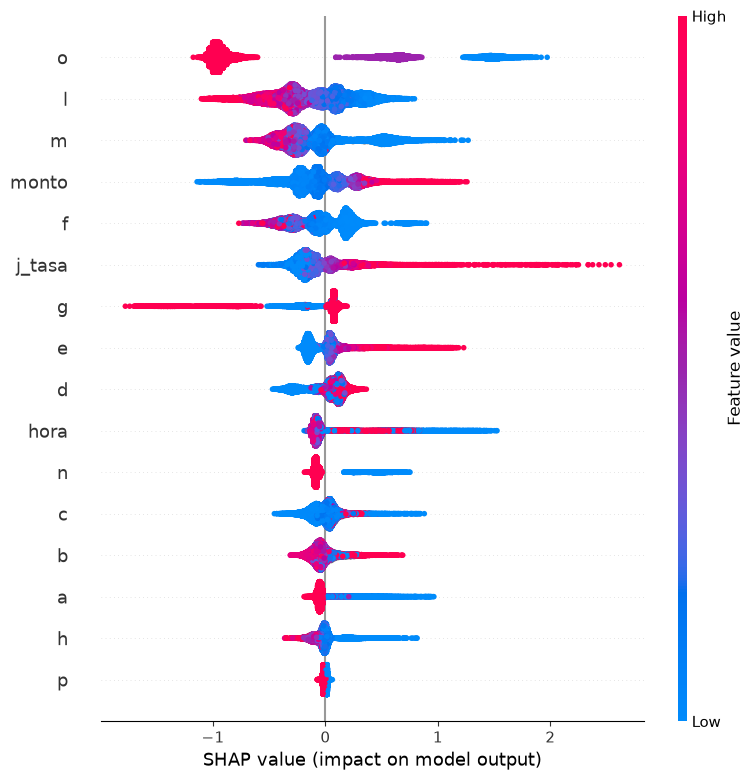

In [8]:
paquete = paquetes["XGBoost sin score"]
modelo = paquete["modelo"]
X_test = paquete["preparador"].transform(datos_sin_etiqueta)

# pred_contribs=True devuelve el valor SHAP de cada variable para cada transacción.
# iteration_range usa solo los árboles elegidos por el early stopping, igual que las predicciones.
valores = modelo.get_booster().predict(
    xgb.DMatrix(X_test, enable_categorical=True),
    pred_contribs=True,
    iteration_range=(0, modelo.best_iteration + 1),
)
# La última columna es el valor base, común a todas las transacciones
shap_test = pd.DataFrame(valores[:, :-1], columns=X_test.columns, index=X_test.index)

# El gráfico necesita números para colorear: las categorías se reemplazan por sus códigos internos,
# que siguen el orden alfabético (en o: N = 0, Y = 1, nulo = 2)
X_grafico = X_test.copy()
for columna in X_grafico.select_dtypes("category"):
    X_grafico[columna] = X_grafico[columna].cat.codes

shap.summary_plot(shap_test.to_numpy(), X_grafico)

In [9]:
nulos_b = X_test["b"].isna()
print(f"Transacciones de test con b nula: {nulos_b.sum():,}")
print(f"Efecto promedio de b cuando es nula: {shap_test.loc[nulos_b, 'b'].mean():.3f}")
print(f"Efecto promedio absoluto de b cuando tiene dato: {shap_test.loc[~nulos_b, 'b'].abs().mean():.3f}")

Transacciones de test con b nula: 331
Efecto promedio de b cuando es nula: 0.093
Efecto promedio absoluto de b cuando tiene dato: 0.083


**Observaciones:**
- Las variables más importantes para el modelo coinciden con las del EDA: `o`, `l`, `m`, `monto`, `f` y `j_tasa`.
- Las direcciones son coherentes con el EDA: `o = N` aumenta el riesgo y `o` vacía lo reduce;
  valores bajos de `l`, `m` y `f` aumentan el riesgo; montos altos y categorías de `j` con más fraude
  histórico también; y la hora aumenta el riesgo en la madrugada y la noche.
- `monto` y `e` pesan más en el modelo que en el análisis univariado: aportan en combinación con otras variables.
- `d` muestra la dirección contraria a la del EDA. Como está correlacionada con `m`, el modelo toma la señal
  principal de `m`, y el efecto de `d` es el que queda una vez conocida `m`.
- Las transacciones con `b` vacía tienen un efecto pequeño, similar al de `b` con dato: el modelo
  no aprendió el incidente de datos como señal de riesgo.
- Como las variables están anonimizadas, esta interpretación verifica la coherencia del modelo,
  pero no explica las causas del fraude.